In [1]:
import math
from random import uniform, seed

import numpy as np
import matplotlib.pyplot as plt

In [2]:
def gaussian(mu, sigma, n):
    g = []
    while len(g) < n:
        u1 = uniform(-1, 1)
        u2 = uniform(-1, 1)
        s = u1 * u1 + u2 * u2
        if 0 < s < 1:
            k = (-2 * math.log(s) / s) ** 0.5
            g.append(mu + sigma * u1 * k)
            if len(g) < n:
                g.append(mu + sigma * u2 * k)
    return g

In [3]:

def generate_class(mu, cov, n):
   
    cov = np.array(cov, dtype=float)
    vals, vecs = np.linalg.eigh(cov)
    c_sqrt = vecs @ np.diag(np.sqrt(vals)) @ vecs.T
    Z = np.array([gaussian(0, 1, n), gaussian(0, 1, n)])   # 2 x n
    return (np.array(mu, dtype=float)[:, None] + c_sqrt @ Z).T  # n x 2

In [4]:
def estimate_isotropic(train):
    mu = train.mean(axis=0)
    s2 = np.sum((train - mu) ** 2) / (2 * len(train))
    return mu, np.array([[s2, 0], [0, s2]])


def estimate_diagonal(train):
    mu = train.mean(axis=0)
    return mu, np.diag(train.var(axis=0))


def estimate_full(train):
    mu = train.mean(axis=0)
    d = train - mu
    return mu, d.T @ d / len(train)

In [5]:
def log_gaussian(points, mu, cov):
    diff = points - mu
    det = np.linalg.det(cov)
    inv = np.linalg.inv(cov)
    quad = np.einsum("ij,jk,ik->i", diff, inv, diff)
    return -math.log(2 * math.pi) - 0.5 * math.log(det) - 0.5 * quad


def classify(points, mus, covs):
    scores = np.array([log_gaussian(points, m, c) for m, c in zip(mus, covs)])
    return np.argmax(scores, axis=0) + 1          # classes numbered 1..K


def confusion_matrix(actual, predicted, k=3):
    cm = np.zeros((k, k), dtype=int)
    for a, p in zip(actual, predicted):
        cm[a - 1][p - 1] += 1
    return cm



In [6]:
def plot_boundaries(tests, mus, covs, lim,title):
    xs = np.linspace(lim[0], lim[1], 500)
    X, Y = np.meshgrid(xs, xs)
    grid = np.c_[X.ravel(), Y.ravel()]
    decision = (classify(grid, mus, covs) - 1).reshape(X.shape)

    plt.figure(figsize=(8, 6))
    for i, t in enumerate(tests, 1):
        plt.scatter(t[:, 0], t[:, 1], s=5, alpha=0.5, label=f"Class {i}")
    plt.contour(X, Y, decision, levels=[0.5, 1.5], linewidths=2)
    for m in mus:
        plt.scatter(m[0], m[1], marker="x", s=100, linewidths=3)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()



In [ ]:
def run_experiment(specs, estimator, plot_lim, n=10000, train_n=8000, title=""):
    # generate data
    data = [generate_class(mu, cov, n) for mu, cov in specs]
    for i, (mu, cov) in enumerate(specs, 1):
        print(f"Class {i}  true mean: {mu}  true covariance: {np.array(cov).tolist()}")
        print("  first 5 points:", data[i - 1][:5].round(3).tolist())

    # train / test split
    train = [d[:train_n] for d in data]
    test = [d[train_n:] for d in data]

    # MLE parameters
    mus, covs = [], []
    print("\nEstimated parameters")
    for i, t in enumerate(train, 1):
        mu, cov = estimator(t)
        mus.append(mu)
        covs.append(cov)
        print(f"Class {i}  mean: {mu.round(4).tolist()}")
        print(f"         covariance: {np.array(cov).round(4).tolist()}")

    # classify test data
    pts = np.vstack(test)
    actual = np.concatenate([[i] * len(t) for i, t in enumerate(test, 1)])
    predicted = classify(pts, mus, covs)

    # result
    correct = int(np.sum(actual == predicted))
    print("\nTraining points per class:", train_n)
    print("Testing points per class:", len(test[0]))
    print("Total test points:", len(actual))
    print("Correct predictions:", correct)
    print("Accuracy (%):", 100 * correct / len(actual))

    cm = confusion_matrix(actual, predicted, len(specs))
    print("\nConfusion Matrix (rows = actual, cols = predicted):")
    print(cm)

    #  plot
    plot_boundaries(test, mus, covs, plot_lim, f"Decision Boundaries {title}")
    plot_roc(actual, posteriors(pts, mus, covs))


In [8]:
def posteriors(points, mus, covs):
    ll = np.array([log_gaussian(points, m, c) for m, c in zip(mus, covs)])
    ll -= ll.max(axis=0)
    p = np.exp(ll)
    return p / p.sum(axis=0)


def roc_curve(is_positive, score):
    order = np.argsort(-score)
    y = is_positive[order].astype(float)
    P = y.sum()
    N = len(y) - P
    tp = np.concatenate([[0], np.cumsum(y)])
    fp = np.concatenate([[0], np.cumsum(1 - y)])
    tpr = tp / P
    fpr = fp / N
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
    return fp, tp, fpr, tpr, auc


def plot_roc(actual, post):
    plt.figure(figsize=(7, 6))
    print("\nROC (one-vs-rest) AUC:")
    for k in range(post.shape[0]):
        fp, tp, fpr, tpr, auc = roc_curve(actual == k + 1, post[k])
        print(f"  Class {k + 1}: AUC = {auc:.4f}   "
              f"(max TP = {int(tp[-1])}, max FP = {int(fp[-1])})")
        plt.plot(fpr, tpr, linewidth=2, label=f"Class {k + 1} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves ")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

Class 1  true mean: [2, 3]  true covariance: [[1, 0], [0, 1]]
  first 5 points: [[2.859, 2.249], [2.756, 1.394], [2.84, 4.599], [3.419, 1.772], [2.628, 3.418]]
Class 2  true mean: [7, 8]  true covariance: [[4, 0], [0, 4]]
  first 5 points: [[8.387, 8.451], [8.205, 8.268], [7.203, 7.156], [11.871, 5.979], [7.568, 7.216]]
Class 3  true mean: [11, 12]  true covariance: [[9, 0], [0, 9]]
  first 5 points: [[8.738, 12.853], [12.89, 18.505], [8.983, 13.998], [7.59, 13.462], [15.77, 13.875]]

Estimated parameters
Class 1  mean: [2.0158, 2.9976]
         covariance: [[1.0049, 0.0], [0.0, 1.0049]]
Class 2  mean: [7.0069, 8.0105]
         covariance: [[3.9998, 0.0], [0.0, 3.9998]]
Class 3  mean: [11.0235, 12.0311]
         covariance: [[8.955, 0.0], [0.0, 8.955]]

Training points per class: 8000
Testing points per class: 2000
Total test points: 6000
Correct predictions: 5468
Accuracy (%): 91.13333333333334

Confusion Matrix (rows = actual, cols = predicted):
[[1990   10    0]
 [  16 1806  178]
 [

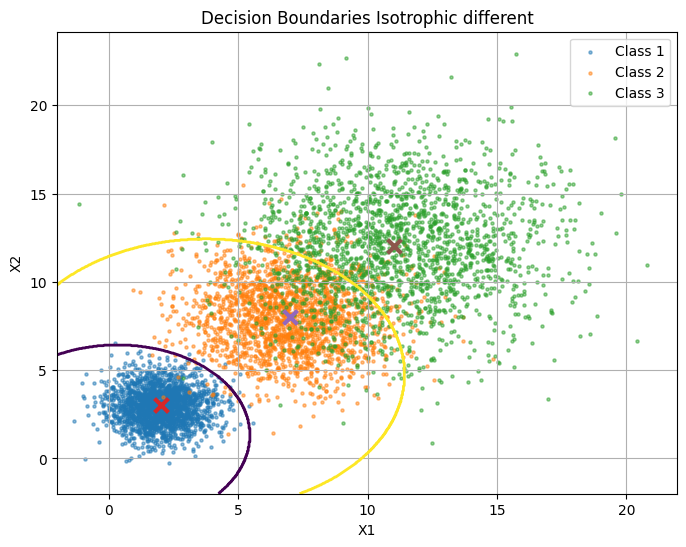


ROC (one-vs-rest) AUC:
  Class 1: AUC = 0.9998   (max TP = 2000, max FP = 4000)
  Class 2: AUC = 0.9690   (max TP = 2000, max FP = 4000)
  Class 3: AUC = 0.9718   (max TP = 2000, max FP = 4000)


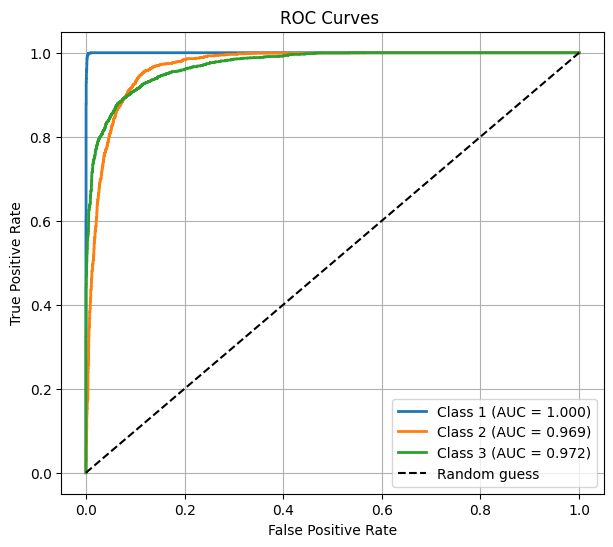

In [9]:

specs = [
    ([2, 3],   [[1, 0], [0, 1]]),
    ([7, 8], [[4, 0], [0, 4]]),
    ([11, 12], [[9, 0], [0, 9]]),
]

run_experiment(specs, estimate_isotropic, plot_lim=(-2, 14), title="Isotrophic different")



Class 1  true mean: [2, 3]  true covariance: [[9, 0], [0, 4]]
  first 5 points: [[-0.48, 6.441], [3.304, -1.812], [4.368, 2.347], [0.793, 3.989], [6.465, 1.24]]
Class 2  true mean: [7, 8]  true covariance: [[1, 0], [0, 9]]
  first 5 points: [[7.07, 5.586], [6.071, 6.556], [4.769, 10.64], [4.366, 10.308], [6.986, 5.888]]
Class 3  true mean: [11, 12]  true covariance: [[4, 0], [0, 1]]
  first 5 points: [[8.745, 12.393], [9.864, 13.067], [8.785, 13.274], [8.662, 11.498], [6.947, 12.351]]

Estimated parameters
Class 1  mean: [2.0037, 2.9668]
         covariance: [[6.4795, 0.0], [0.0, 6.4795]]
Class 2  mean: [6.991, 7.9705]
         covariance: [[5.1447, 0.0], [0.0, 5.1447]]
Class 3  mean: [11.0116, 11.9791]
         covariance: [[2.48, 0.0], [0.0, 2.48]]

Training points per class: 8000
Testing points per class: 2000
Total test points: 6000
Correct predictions: 5467
Accuracy (%): 91.11666666666666

Confusion Matrix (rows = actual, cols = predicted):
[[1835  165    0]
 [ 143 1739  118]
 [  

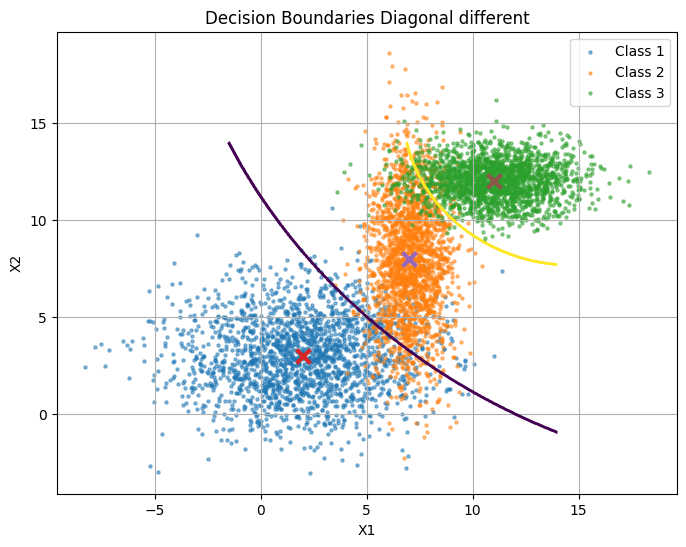


ROC (one-vs-rest) AUC:
  Class 1: AUC = 0.9896   (max TP = 2000, max FP = 4000)
  Class 2: AUC = 0.9674   (max TP = 2000, max FP = 4000)
  Class 3: AUC = 0.9939   (max TP = 2000, max FP = 4000)


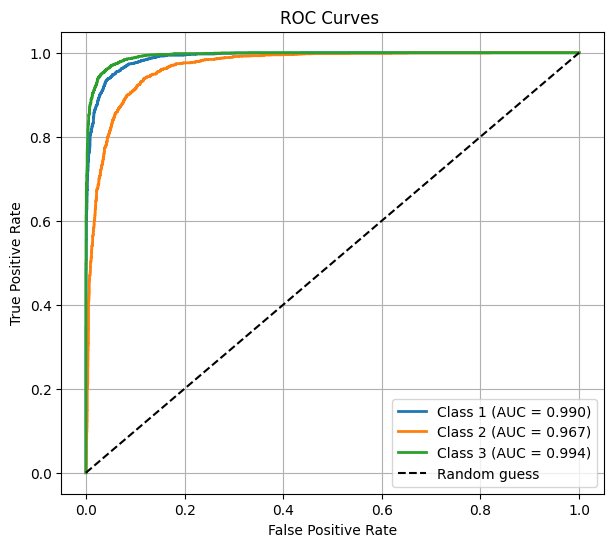

In [10]:

specs = [
    ([2, 3],   [[9, 0], [0, 4]]),
    ([7, 8],   [[1, 0], [0, 9]]),
    ([11, 12], [[4, 0], [0, 1]]),
]

run_experiment(specs, estimate_isotropic, plot_lim=(-2, 14), title="Diagonal different")


Class 1  true mean: [2, 3]  true covariance: [[2, 1], [0, 1]]
  first 5 points: [[0.316, 4.122], [1.447, 1.712], [3.42, 3.006], [0.708, 2.42], [2.288, 1.681]]
Class 2  true mean: [7, 8]  true covariance: [[2, 0], [0, 1]]
  first 5 points: [[7.841, 7.104], [7.423, 6.978], [7.415, 6.713], [8.069, 7.893], [5.944, 8.349]]
Class 3  true mean: [11, 12]  true covariance: [[3, 1], [0, 2]]
  first 5 points: [[14.533, 13.062], [11.682, 13.835], [7.169, 9.067], [9.774, 12.065], [12.535, 11.643]]

Estimated parameters
Class 1  mean: [2.0222, 3.0075]
         covariance: [[1.5031, 0.0], [0.0, 1.5031]]
Class 2  mean: [6.9998, 7.982]
         covariance: [[1.4869, 0.0], [0.0, 1.4869]]
Class 3  mean: [10.9837, 12.0161]
         covariance: [[2.4863, 0.0], [0.0, 2.4863]]

Training points per class: 8000
Testing points per class: 2000
Total test points: 6000
Correct predictions: 5906
Accuracy (%): 98.43333333333334

Confusion Matrix (rows = actual, cols = predicted):
[[1998    2    0]
 [   1 1946   53]


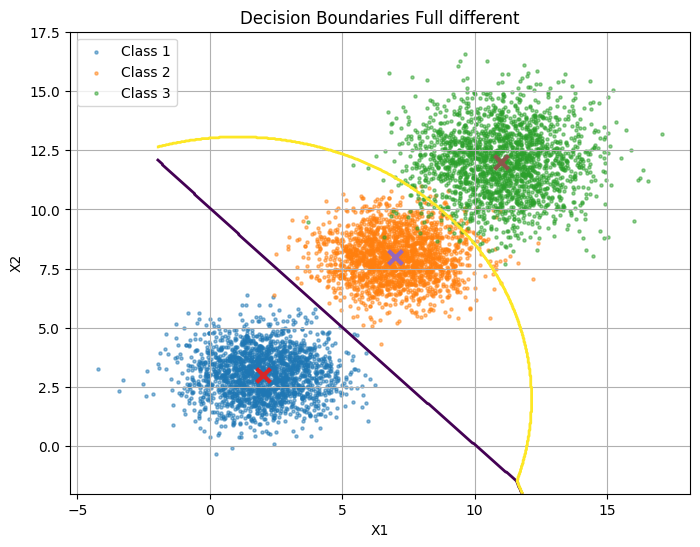


ROC (one-vs-rest) AUC:
  Class 1: AUC = 1.0000   (max TP = 2000, max FP = 4000)
  Class 2: AUC = 0.9987   (max TP = 2000, max FP = 4000)
  Class 3: AUC = 0.9988   (max TP = 2000, max FP = 4000)


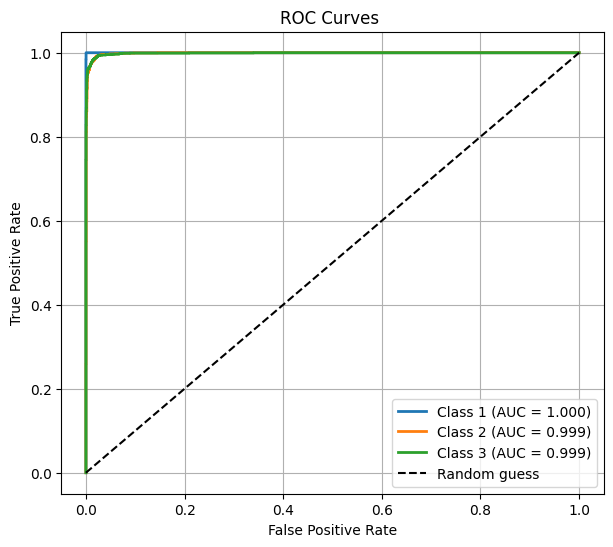

In [11]:

specs = [
    ([2, 3],   [[2, 1], [0, 1]]),
    ([7, 8],   [[2, 0], [0, 1]]),
    ([11, 12], [[3, 1], [0, 2]]),
]

run_experiment(specs, estimate_isotropic, plot_lim=(-2, 14), title="Full different")
